# IE 522 Final Project: Fresh-Food Access in Rural Appalachia

Starter notebook. The **data loading** and **feasibility check** are provided. **Section 3, the model, is yours to write** (see `notes/07-formulation-worksheet.md`).

Before running, build the inputs from the project root:
- `.venv/bin/python analysis/03_store_type_access.py`
- `.venv/bin/python analysis/04_build_model_data.py`

Costs and budget come from `notes/06-cost-parameters.md`. Cite them in the report.

## 1. Settings

In [1]:
import time
from pathlib import Path

import gurobipy as gp
from gurobipy import GRB
import pandas as pd

DATA = Path("..") / "data" / "model"

INSTANCE = "tn"        # "tn", "central", "south_central", "all"
LEVEL = "block"        # "block" or "bg" (block groups)
R = 10                 # coverage radius in miles: 5 or 10 (15 has almost no demand)

COST = {               # dollars per funded site, by site_type (notes/06-cost-parameters.md)
    "upgrade_grocery": 25_000,
    "upgrade_convenience": 25_000,
    "new_store": 1_000_000,
}
BUDGET = 3_000_000     # dollars
SITE_TYPES = list(COST)  # site types the model may fund ("dollar" is excluded on purpose)

## 2. Load the data

In [2]:
def load_instance(instance, level, radius, cost=COST, site_types=SITE_TYPES):
    """Read one instance and return the model containers (named as in the formulation)."""
    demand = pd.read_csv(DATA / instance / f"demand_{level}_R{radius}.csv", dtype={"id": str, "county_fips": str})
    sites = pd.read_csv(DATA / instance / "sites.csv", dtype={"id": str, "county_fips": str})
    cover = pd.read_csv(DATA / instance / f"cover_{level}_R{radius}.csv", dtype={"demand_id": str, "site_id": str})
    sites = sites[sites["site_type"].isin(site_types)].copy()
    sites["cost"] = sites["site_type"].map(cost)
    cover = cover[cover["site_id"].isin(sites["id"])]
    N = cover.groupby("demand_id")["site_id"].apply(list).to_dict()  # N_h: sites within R miles of h
    for h in demand["id"]:
        N.setdefault(h, [])
    return dict(
        demand=demand, sites=sites, cover=cover, N=N,
        H=demand["id"].tolist(),                                   # neighborhoods (demand points)
        S=sites["id"].tolist(),                                    # candidate sites
        w=dict(zip(demand["id"], demand["pop"])),                  # w_h: people in neighborhood h
        f=dict(zip(sites["id"], sites["cost"])),                   # f_s: $ to fund site s
        low_income=dict(zip(demand["id"], demand["low_income"])),  # 1 if h is in a low-income tract
        site_type=dict(zip(sites["id"], sites["site_type"])),
    )


inst = load_instance(INSTANCE, LEVEL, R)
demand, sites, cover, N = inst["demand"], inst["sites"], inst["cover"], inst["N"]
H, S, w, f = inst["H"], inst["S"], inst["w"], inst["f"]
low_income, site_type = inst["low_income"], inst["site_type"]
B = BUDGET

print(f"{INSTANCE}, {LEVEL}, R={R} mi")
print(f"neighborhoods |H|: {len(H):,}   people: {demand['pop'].sum():,}")
print(f"candidate sites |S|: {len(S):,}   ", sites["site_type"].value_counts().to_dict())
print(f"coverage pairs: {len(cover):,}")
print(f"people with no candidate site within R: {sum(w[h] for h in H if not N[h]):,}")

tn, block, R=10 mi
neighborhoods |H|: 1,930   people: 41,397
candidate sites |S|: 1,351    {'upgrade_convenience': 959, 'new_store': 249, 'upgrade_grocery': 143}
coverage pairs: 13,803
people with no candidate site within R: 798


## 3. Model

Maximal covering location problem (notes/07-formulation-worksheet.md):

- maximize Σ_h w_h y_h
- subject to y_h ≤ Σ_{s ∈ N_h} x_s for all h (coverage), Σ_s f_s x_s ≤ B (budget)
- x_s ∈ {0,1}; y_h relaxed to [0,1], which is valid because maximization pushes y_h to min(1, Σ x_s), an integer (worksheet Q16)

In [3]:
def build_and_solve(H, S, N, w, f, B, time_limit=600, mip_gap=1e-4, verbose=True):
    m = gp.Model("mclp")
    m.Params.OutputFlag = int(verbose)
    m.Params.TimeLimit = time_limit
    m.Params.MIPGap = mip_gap

    x = m.addVars(S, vtype=GRB.BINARY, name="x")         # x_s = 1 if site s is funded
    y = m.addVars(H, lb=0, ub=1, name="y")               # y_h = 1 if neighborhood h is covered

    m.setObjective(gp.quicksum(w[h] * y[h] for h in H), GRB.MAXIMIZE)
    # only sites in S can cover (lets experiments pass a subset of sites)
    m.addConstrs((y[h] <= gp.quicksum(x[s] for s in N[h] if s in x) for h in H), name="coverage")
    m.addConstr(gp.quicksum(f[s] * x[s] for s in S) <= B, name="budget")

    m.optimize()
    chosen = [s for s in S if x[s].X > 0.5]
    return m, chosen


m, chosen_sites = build_and_solve(H, S, N, w, f, B)
solve_seconds = m.Runtime
obj_value = m.ObjVal
mip_gap = m.MIPGap
print(f"\nstatus {m.Status} | people covered {obj_value:,.0f} | bound {m.ObjBound:,.0f} | "
      f"gap {100 * mip_gap:.3f}% | {solve_seconds:.2f} s | {m.NumVars:,} vars, {m.NumConstrs:,} constraints")

Set parameter Username


Set parameter LicenseID to value 2854889


Academic license - for non-commercial use only - expires 2027-08-20


Set parameter OutputFlag to value 1


Set parameter TimeLimit to value 600


Set parameter MIPGap to value 0.0001


... (41 outputs left out)

Solution count 10: 40478 40475 40473 ... -0


Optimal solution found (tolerance 1.00e-04)


Best objective 4.047800000000e+04, best bound 4.047800000000e+04, gap 0.0000%



status 2 | people covered 40,478 | bound 40,478 | gap 0.000% | 0.02 s | 3,281 vars, 1,931 constraints


## 4. Feasibility check, independent of the solver

This recomputes spending and coverage directly from `chosen_sites` and the raw coverage file. It does not use any Gurobi values. The spec requires this check.

In [4]:
def verify(chosen, budget=BUDGET):
    chosen = set(chosen)
    unknown = chosen - set(S)
    spent = sum(f[s] for s in chosen if s in f)
    covered_ids = set(cover.loc[cover["site_id"].isin(chosen), "demand_id"])
    d = demand[demand["id"].isin(covered_ids)]
    return {
        "sites_funded": len(chosen),
        "by_type": pd.Series([site_type[s] for s in chosen if s in site_type], dtype=object).value_counts().to_dict(),
        "spent_$": spent,
        "within_budget": spent <= budget + 1e-6,
        "unknown_site_ids": len(unknown),
        "people_covered": int(d["pop"].sum()),
        "low_income_people_covered": int(d.loc[d["low_income"] == 1, "pop"].sum()),
        "pct_of_demand_covered": round(100 * d["pop"].sum() / demand["pop"].sum(), 2),
    }

check = verify(chosen_sites)
check

{'sites_funded': 42,
 'by_type': {'upgrade_convenience': 38, 'upgrade_grocery': 2, 'new_store': 2},
 'spent_$': 3000000,
 'within_budget': True,
 'unknown_site_ids': 0,
 'people_covered': 40478,
 'low_income_people_covered': 29509,
 'pct_of_demand_covered': np.float64(97.78)}

In [5]:
# Compare the solver's objective with the independent recount (they should match if the objective is people covered)
if obj_value is not None:
    print("solver objective:", obj_value, "| independent recount:", check["people_covered"])

solver objective: 40478.0 | independent recount: 40478


### Sanity tests (worksheet Part 7)

In [6]:
coverable = sum(w[h] for h in H if N[h])
tests = {
    "B = 0 covers 0 people": build_and_solve(H, S, N, w, f, 0, verbose=False)[0].ObjVal == 0,
    "B = $1B covers everyone coverable": round(build_and_solve(H, S, N, w, f, 1e9, verbose=False)[0].ObjVal) == coverable,
    "upgrades only covers <= base": build_and_solve(
        H, [s for s in S if site_type[s] != "new_store"], N, w, f, B, verbose=False)[0].ObjVal <= obj_value + 1e-6,
    "solver objective == independent recount": round(obj_value) == check["people_covered"],
    "spending within budget": check["within_budget"],
}
print(f"coverable people (at least one candidate within R): {coverable:,}")
tests

coverable people (at least one candidate within R): 40,599


{'B = 0 covers 0 people': True,
 'B = $1B covers everyone coverable': True,
 'upgrades only covers <= base': True,
 'solver objective == independent recount': True,
 'spending within budget': True}

## 5. Results table (for the report)

In [7]:
funded = sites[sites["id"].isin(chosen_sites)][["id", "name", "site_type", "county_fips", "cost"]]
funded.sort_values(["site_type", "county_fips"])

,id,name,site_type,county_fips,cost
2012,P4767920,"Sherwood CDP, TN",new_store,47051,1000000
1887,P4725740,"Farner CDP, TN",new_store,47139,1000000
41,S237624,NEW RIVER GENERAL STORE,upgrade_convenience,47001,25000
91,S1374130,Fast Lap Market & Deli,upgrade_convenience,47009,25000
199,S1118927,Rocky Top Markets 928,upgrade_convenience,47013,25000
267,S1421623,Ten 3 Market & Deli,upgrade_convenience,47025,25000
274,S1603734,Payless Food Mart,upgrade_convenience,47027,25000
279,S1384874,Big O's Hartford 5,upgrade_convenience,47029,25000
299,S1433050,J And S Mini Mart,upgrade_convenience,47029,25000
317,S1452992,Bens Lakewood Market,upgrade_convenience,47031,25000


## 6. Sensitivity analysis

### 6.1 Budget sweep
**Why:** the base case ($3M) almost saturates Tennessee at R = 10, so the decision maker needs to see *how coverage grows with money* and where extra dollars stop paying off. Run for R = 5 and R = 10, since the coverage standard changes how much the budget matters.

Coverage is reported as a **% of demand** because the demand set differs by R: only blocks more than R miles from a grocer count.

In [8]:
RESULTS = Path("..") / "results"
FIGS = Path("..") / "figures"
RESULTS.mkdir(exist_ok=True)
FIGS.mkdir(exist_ok=True)

BUDGETS = [0, 25_000, 50_000, 100_000, 150_000, 200_000, 300_000, 400_000, 500_000,
           750_000, 1_000_000, 1_500_000, 2_000_000, 2_500_000, 3_000_000, 4_000_000, 5_000_000]

rows = []
for radius in [5, 10]:
    d = load_instance(INSTANCE, LEVEL, radius)
    total = d["demand"]["pop"].sum()
    coverable = sum(d["w"][h] for h in d["H"] if d["N"][h])
    for budget in BUDGETS:
        mod, chosen = build_and_solve(d["H"], d["S"], d["N"], d["w"], d["f"], budget, verbose=False)
        types = pd.Series([d["site_type"][s] for s in chosen], dtype=object).value_counts()
        rows.append({
            "R_mi": radius, "budget": budget, "people_covered": round(mod.ObjVal),
            "pct_covered": 100 * mod.ObjVal / total, "pct_of_coverable": 100 * mod.ObjVal / coverable,
            "demand_pop": total, "coverable_pop": coverable,
            "upgrades": int(types.get("upgrade_grocery", 0) + types.get("upgrade_convenience", 0)),
            "new_stores": int(types.get("new_store", 0)),
            "spent": sum(d["f"][s] for s in chosen), "gap_pct": 100 * mod.MIPGap, "seconds": mod.Runtime,
        })

sweep = pd.DataFrame(rows)
sweep.to_csv(RESULTS / f"budget_sweep_{INSTANCE}_{LEVEL}.csv", index=False)
sweep[["R_mi", "budget", "people_covered", "pct_covered", "upgrades", "new_stores", "gap_pct", "seconds"]].round(2)

,R_mi,budget,people_covered,pct_covered,upgrades,new_stores,gap_pct,seconds
0,5,0,0,-0.00,0,0,0.00,0.01
1,5,25000,9600,2.09,1,0,0.00,0.04
2,5,50000,17125,3.73,2,0,0.00,0.02
3,5,100000,30478,6.63,4,0,0.00,0.02
4,5,150000,43284,9.42,6,0,0.00,0.02
5,5,200000,55280,12.03,8,0,0.00,0.02
6,5,300000,76334,16.61,12,0,0.00,0.02
7,5,400000,95655,20.81,16,0,0.00,0.02
8,5,500000,113336,24.66,20,0,0.00,0.02
9,5,750000,153189,33.33,30,0,0.00,0.02


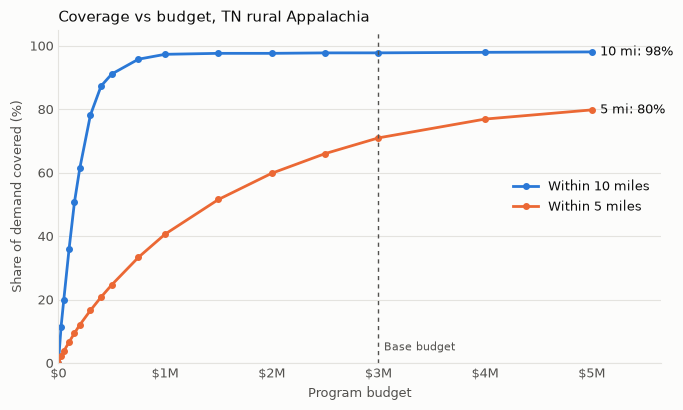

In [9]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# Validated categorical slots 1-2 (dataviz reference palette, light mode)
COLORS = {10: "#2a78d6", 5: "#eb6834"}
INK, INK2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
money = FuncFormatter(lambda v, _: "$0" if v == 0 else (f"${v/1e6:g}M" if v >= 1e6 else f"${v/1e3:g}k"))

def style(ax):
    ax.set_facecolor(SURFACE)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
    for side in ["left", "bottom"]:
        ax.spines[side].set_color(GRID)
    ax.tick_params(colors=INK2, labelsize=9, length=0)
    ax.grid(axis="y", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)

fig, ax = plt.subplots(figsize=(7, 4.2), facecolor=SURFACE)
style(ax)
for radius in [10, 5]:
    s = sweep[sweep["R_mi"] == radius]
    ax.plot(s["budget"], s["pct_covered"], color=COLORS[radius], linewidth=2, marker="o", markersize=4,
            label=f"Within {radius} miles")
    last = s.iloc[-1]
    ax.annotate(f"{radius} mi: {last['pct_covered']:.0f}%", (last["budget"], last["pct_covered"]),
                xytext=(6, 0), textcoords="offset points", va="center", fontsize=9, color=INK)
ax.axvline(BUDGET, color=INK2, linewidth=1, linestyle=(0, (3, 3)))
ax.annotate("Base budget", (BUDGET, 4), xytext=(4, 0), textcoords="offset points", fontsize=8, color=INK2)
ax.xaxis.set_major_formatter(money)
ax.set_ylim(0, 105)
ax.set_xlim(0, max(BUDGETS) * 1.13)
ax.set_xlabel("Program budget", color=INK2, fontsize=9)
ax.set_ylabel("Share of demand covered (%)", color=INK2, fontsize=9)
ax.set_title(f"Coverage vs budget, {INSTANCE.upper()} rural Appalachia", loc="left", fontsize=11, color=INK)
ax.legend(frameon=False, fontsize=9, labelcolor=INK, loc="center right")
fig.tight_layout()
fig.savefig(FIGS / f"fig_budget_curve_{INSTANCE}.png", dpi=200)
plt.show()

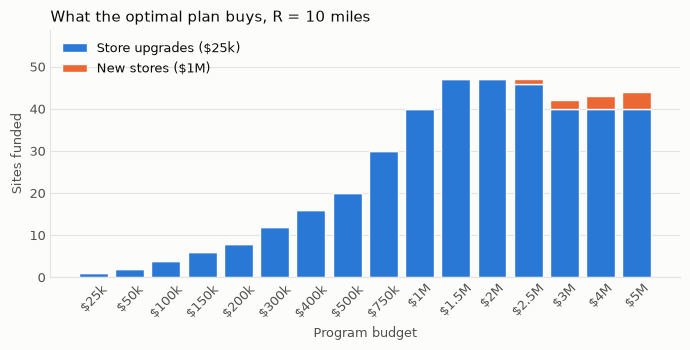

In [10]:
# Site mix by budget, R = 10: upgrades vs new stores (2-px surface gap between stacked segments)
s = sweep[(sweep["R_mi"] == 10) & (sweep["budget"] > 0)]
labels = [money(b, None) for b in s["budget"]]
fig, ax = plt.subplots(figsize=(7, 3.6), facecolor=SURFACE)
style(ax)
ax.bar(labels, s["upgrades"], color=COLORS[10], edgecolor=SURFACE, linewidth=1, label="Store upgrades ($25k)")
ax.bar(labels, s["new_stores"], bottom=s["upgrades"], color=COLORS[5], edgecolor=SURFACE, linewidth=1,
       label="New stores ($1M)")
ax.set_ylim(0, (s["upgrades"] + s["new_stores"]).max() * 1.25)
ax.set_ylabel("Sites funded", color=INK2, fontsize=9)
ax.set_xlabel("Program budget", color=INK2, fontsize=9)
ax.tick_params(axis="x", rotation=45)
ax.set_title("What the optimal plan buys, R = 10 miles", loc="left", fontsize=11, color=INK)
ax.legend(frameon=False, fontsize=9, labelcolor=INK, loc="upper left")
fig.tight_layout()
fig.savefig(FIGS / f"fig_site_mix_{INSTANCE}.png", dpi=200)
plt.show()

### 6.2 Cost sensitivity: upgrade cost vs new-store cost
**Why:** the budget sweep showed upgrades dominate at $25k vs $1M. The cited upgrade costs range from about $5k to $90k, and new-store costs from about $0.8M to $2.1M (notes/06). This tests whether the recommendation, "fund upgrades and almost never new stores," survives that uncertainty, and at what upgrade cost new stores start to win.

The budget is held fixed per radius: **$1M at R = 10** (where coverage flattens) and **$3M at R = 5** (base case). Upgrade costs run past the realistic range, up to $1M, to locate the crossover.

In [11]:
UPGRADE_COSTS = [5_000, 10_000, 25_000, 50_000, 90_000, 150_000, 250_000, 500_000, 1_000_000]
NEW_STORE_COSTS = [800_000, 1_000_000, 2_100_000]
FIXED_BUDGET = {10: 1_000_000, 5: 3_000_000}

rows = []
for radius, budget in FIXED_BUDGET.items():
    for c_new in NEW_STORE_COSTS:
        for c_up in UPGRADE_COSTS:
            d = load_instance(INSTANCE, LEVEL, radius,
                              cost={"upgrade_grocery": c_up, "upgrade_convenience": c_up, "new_store": c_new})
            mod, chosen = build_and_solve(d["H"], d["S"], d["N"], d["w"], d["f"], budget, verbose=False)
            types = pd.Series([d["site_type"][s] for s in chosen], dtype=object).value_counts()
            n_new = int(types.get("new_store", 0))
            rows.append({
                "R_mi": radius, "budget": budget, "upgrade_cost": c_up, "new_store_cost": c_new,
                "cost_ratio_new_to_upgrade": c_new / c_up,
                "people_covered": round(mod.ObjVal), "pct_covered": 100 * mod.ObjVal / d["demand"]["pop"].sum(),
                "upgrades": len(chosen) - n_new, "new_stores": n_new,
                "pct_budget_on_new_stores": 100 * n_new * c_new / budget,
                "gap_pct": 100 * mod.MIPGap, "seconds": mod.Runtime,
            })

costs = pd.DataFrame(rows)
costs.to_csv(RESULTS / f"cost_sensitivity_{INSTANCE}_{LEVEL}.csv", index=False)
costs[costs["new_store_cost"] == 1_000_000][
    ["R_mi", "upgrade_cost", "pct_covered", "upgrades", "new_stores", "pct_budget_on_new_stores", "gap_pct", "seconds"]
].round(2)

,R_mi,upgrade_cost,pct_covered,upgrades,new_stores,pct_budget_on_new_stores,gap_pct,seconds
9,10,5000,97.62,47,0,0.00,0.00,0.01
10,10,10000,97.62,47,0,0.00,0.00,0.01
11,10,25000,97.32,40,0,0.00,0.00,0.01
12,10,50000,91.11,20,0,0.00,0.00,0.01
13,10,90000,74.98,11,0,0.00,0.00,0.01
14,10,150000,50.63,6,0,0.00,0.00,0.01
15,10,250000,36.00,4,0,0.00,0.00,0.01
16,10,500000,19.82,2,0,0.00,0.00,0.01
17,10,1000000,11.49,1,0,0.00,0.00,0.01
36,5,5000,81.80,276,1,33.33,0.00,0.05


In [12]:
# Crossover: smallest upgrade cost at which the optimal plan funds any new store
crossover = (costs[costs["new_stores"] > 0]
             .groupby(["R_mi", "new_store_cost"])["upgrade_cost"].min()
             .reindex(pd.MultiIndex.from_product([[10, 5], NEW_STORE_COSTS], names=["R_mi", "new_store_cost"])))
crossover.rename("first_upgrade_cost_with_a_new_store").to_frame()

first_upgrade_cost_with_a_new_store
R_mi new_store_cost                                     
10   800000                                          NaN
     1000000                                         NaN
     2100000                                         NaN
5    800000                                       5000.0
     1000000                                      5000.0
     2100000                                         NaN

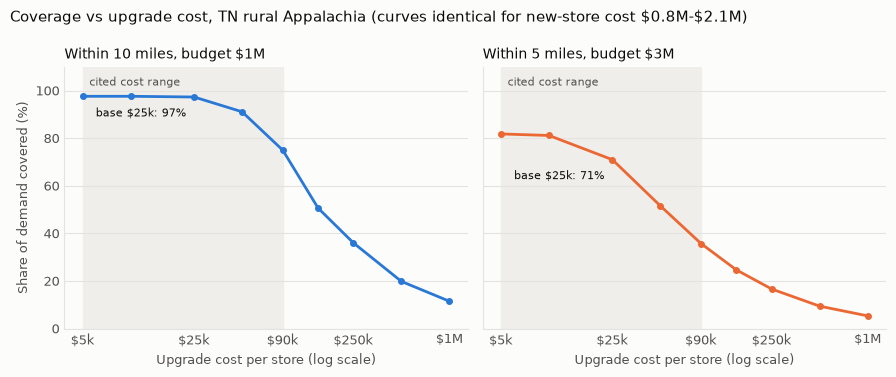

In [13]:
# New-store cost ($0.8M / $1M / $2.1M) gives identical curves (see crossover table), so one line per panel
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8), facecolor=SURFACE, sharey=True)
money_ticks = [5_000, 25_000, 90_000, 250_000, 1_000_000]
for ax, radius in zip(axes, [10, 5]):
    style(ax)
    ax.axvspan(5_000, 90_000, color="#efeeea", zorder=0)
    ax.annotate("cited cost range", (5_500, 101), fontsize=8, color=INK2, va="bottom")
    s = costs[(costs["R_mi"] == radius) & (costs["new_store_cost"] == 1_000_000)]
    ax.plot(s["upgrade_cost"], s["pct_covered"], color=COLORS[radius], linewidth=2, marker="o", markersize=4)
    base = s[s["upgrade_cost"] == COST["upgrade_grocery"]].iloc[0]
    ax.annotate(f"base \\$25k: {base['pct_covered']:.0f}%", (base["upgrade_cost"], base["pct_covered"]),
                xytext=(-6, -14), textcoords="offset points", ha="right", fontsize=8, color=INK)
    ax.set_xscale("log")
    ax.set_xticks(money_ticks)
    ax.xaxis.set_major_formatter(money)
    ax.minorticks_off()
    ax.set_ylim(0, 110)
    ax.set_xlabel("Upgrade cost per store (log scale)", color=INK2, fontsize=9)
    ax.set_title(f"Within {radius} miles, budget {money(FIXED_BUDGET[radius], None)}",
                 loc="left", fontsize=10, color=INK)
axes[0].set_ylabel("Share of demand covered (%)", color=INK2, fontsize=9)
fig.suptitle(f"Coverage vs upgrade cost, {INSTANCE.upper()} rural Appalachia "
             "(curves identical for new-store cost \\$0.8M-\\$2.1M)", x=0.01, ha="left", fontsize=10.5, color=INK)
fig.tight_layout()
fig.savefig(FIGS / f"fig_cost_sensitivity_{INSTANCE}.png", dpi=200)
plt.show()